# A small BALM example

Fit two shared templates to 24 synthetic weighted networks on 12 nodes, inspect memberships, and predict withheld entries. The notebook calls the same BALM model and sampler as the experiment runners, with a smaller initialization search and shorter chain.

Open this notebook from the repository root after installing `requirements.txt`. The first fit includes JAX compilation. For manuscript-sized runs, use the commands in [README.md](README.md).

In [2]:
import os
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[name] = "1"
os.environ.setdefault("JAX_PLATFORM_NAME", "cpu")
os.environ.setdefault("XLA_FLAGS", "--xla_cpu_multi_thread_eigen=false intra_op_parallelism_threads=1")

from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.metrics import roc_auc_score
from model import FitResult, fit_balm

%matplotlib inline

## Generate networks

`Z`, `Y`, and the training mask have shape `(subjects, node_pairs)`. Columns follow `np.triu_indices(n, 1)`. `Z` records edge presence; `Y` contains signed continuous scores for present edges. Absent edges contribute only to the presence likelihood.

In [3]:
rng = np.random.default_rng(12345)
n, subjects, templates, rank = 12, 24, 2, 2
row, col = np.triu_indices(n, 1)
pairs = len(row)
Q_true = []
for _ in range(templates):
    basis, _ = np.linalg.qr(rng.normal(size=(n, rank)))
    matrix = (basis * np.array([1.0, -0.7])) @ basis.T
    edges = matrix[row, col]
    Q_true.append(0.6 * edges / np.sqrt(np.mean(edges ** 2)))
Q_true = np.asarray(Q_true)
W_true = rng.dirichlet(np.full(templates, 1 / templates), size=subjects)
mean_score = W_true @ Q_true
Z = rng.binomial(1, expit(-0.3 + 2.0 * mean_score))
Y = np.where(Z == 1, mean_score + 0.2 * rng.normal(size=Z.shape), 0.0)
train_mask = np.zeros(Z.shape, dtype=bool)
for participant in range(subjects):
    train_mask[participant, rng.choice(pairs, int(0.8 * pairs), replace=False)] = True
test_mask = ~train_mask
print(f"{subjects} networks, {n} nodes, {pairs} node pairs; {train_mask.sum()} training entries")

24 networks, 12 nodes, 66 node pairs; 1248 training entries


## Fit BALM

`M` is the number of templates and `K` their spectral rank. `alpha=1` is the total Dirichlet concentration. Initialization uses training observations. The short settings below demonstrate the API; the manuscript runners retain their full initialization and sampling schedules.

In [4]:
started = time.perf_counter()
fit = fit_balm(
    Z, Y, train_mask, n=n, M=templates, K=rank,
    alpha=1.0, seed=12345, warmup=500, draws=1500,
    max_tree_depth=7,
    initialization={"profile": "demo", "screen_iterations": 20,
                    "refine_candidates": 1, "maxiter": 60},
)
print(f"Fit completed in {time.perf_counter() - started:.1f} seconds")
print(f"Retained draws: {len(fit.samples['W'])}")

Fit completed in 52.9 seconds
Retained draws: 1500


## Inspect recovery and prediction

The generating templates are used **after fitting** to align template labels for this synthetic comparison. For observed data, `fit.aligned_summary()` aligns to a fitted reference draw instead. `predict()` averages over retained draws; `presence_probability` and `log_density` are available for each network entry.

If `fit` is already available in the current kernel, run from this section onward to update the comparisons and figures without fitting again.

In [5]:
summary = fit.aligned_summary(reference=Q_true)
Q_est = summary["Q_mean"]
W_est = summary["W_mean"]
prediction = fit.predict(Z, Y, mask=test_mask)
metrics = pd.Series({
    "Template RMSE": np.sqrt(np.mean((Q_est - Q_true) ** 2)),
    "Membership MAE": np.mean(np.abs(W_est - W_true)),
    "Test topology AUC": roc_auc_score(Z[test_mask], prediction["presence_probability"][test_mask]),
    "Test mean hurdle log score": np.mean(prediction["log_density"][test_mask]),
})
metrics.round(4)

Template RMSE                 0.0931
Membership MAE                0.0428
Test topology AUC             0.7277
Test mean hurdle log score   -0.5226
dtype: float64

## Prediction using the true generating parameters

Compare the fitted posterior predictions with the known data-generating model on the **same test entries**. The reference uses the true templates, memberships, coupling coefficients and noise scale; it does not fit another model. Higher AUC and mean hurdle log score are better. The reference is not a strict upper bound on a finite test sample.

In [6]:
from scipy.stats import norm

a0_true, a1_true, sigma_true = -0.3, 2.0, 0.2
logits_true = a0_true + a1_true * mean_score
probability_true = expit(logits_true)
log_density_true = np.where(
    Z == 1,
    -np.logaddexp(0, -logits_true)
    + norm.logpdf(Y, loc=mean_score, scale=sigma_true),
    -np.logaddexp(0, logits_true),
)
prediction_comparison = pd.DataFrame({
    "BALM posterior prediction": [
        metrics["Test topology AUC"],
        metrics["Test mean hurdle log score"],
    ],
    "True generating parameters": [
        roc_auc_score(Z[test_mask], probability_true[test_mask]),
        np.mean(log_density_true[test_mask]),
    ],
}, index=["Test topology AUC", "Test mean hurdle log score"])
prediction_comparison.round(4)

,BALM posterior prediction,True generating parameters
Test topology AUC,0.7277,0.7362
Test mean hurdle log score,-0.5226,-0.4845


## True and estimated templates Q

Each column shows one template: its generating matrix above and its aligned posterior mean below. All panels use the same grayscale, centered at zero; darker entries are more positive. Diagonal entries are omitted because the model uses off-diagonal node pairs. `Q_est` contains the estimated upper-triangle entries, with shape `(templates, node_pairs)`.

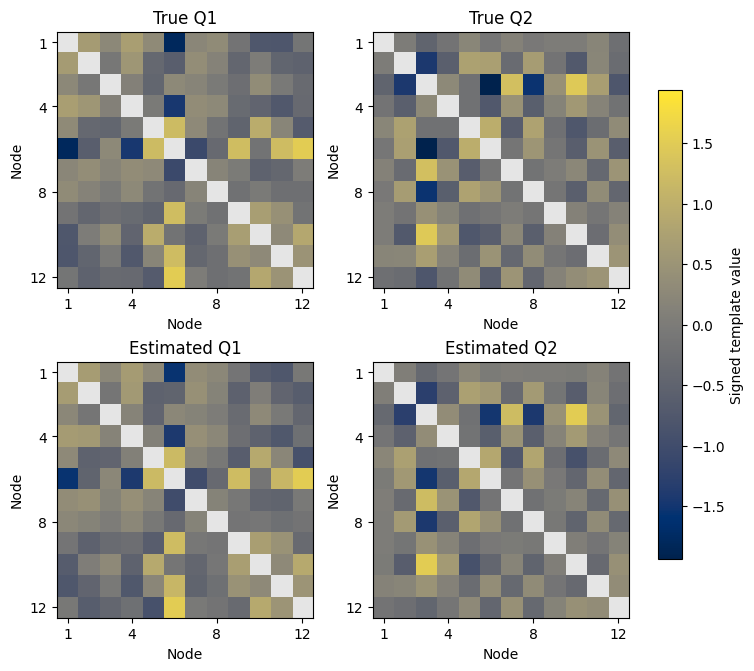

In [7]:
def template_matrices(edge_values):
    matrices = np.zeros((templates, n, n))
    matrices[:, row, col] = edge_values
    matrices[:, col, row] = edge_values
    diagonal = np.broadcast_to(np.eye(n, dtype=bool), matrices.shape)
    return np.ma.array(matrices, mask=diagonal)

Q_true_matrices = template_matrices(Q_true)
Q_est_matrices = template_matrices(Q_est)
limit = max(np.abs(Q_true).max(), np.abs(Q_est).max())
grayscale = plt.get_cmap("cividis").copy()
grayscale.set_bad("0.9")
fig, axes = plt.subplots(2, templates, figsize=(7.5, 6.6),
                         constrained_layout=True, squeeze=False)
for template in range(templates):
    for panel_row, (label, matrices) in enumerate([
        ("True", Q_true_matrices), ("Estimated", Q_est_matrices),
    ]):
        ax = axes[panel_row, template]
        heatmap = ax.imshow(matrices[template], cmap=grayscale,
                            vmin=-limit, vmax=limit, interpolation="nearest")
        ax.set(title=f"{label} Q{template + 1}", xlabel="Node", ylabel="Node")
        ax.set_xticks([0, 3, 7, n - 1], [1, 4, 8, n])
        ax.set_yticks([0, 3, 7, n - 1], [1, 4, 8, n])
fig.colorbar(heatmap, ax=axes.ravel().tolist(), shrink=0.8,
             label="Signed template value")
plt.show()

## True and estimated memberships W

Rows identify the same subjects in both panels; columns identify the matched templates. Each row sums to one. The shared scale runs from zero (white) to one (black). `W_est` contains the aligned posterior mean memberships, with shape `(subjects, templates)`.

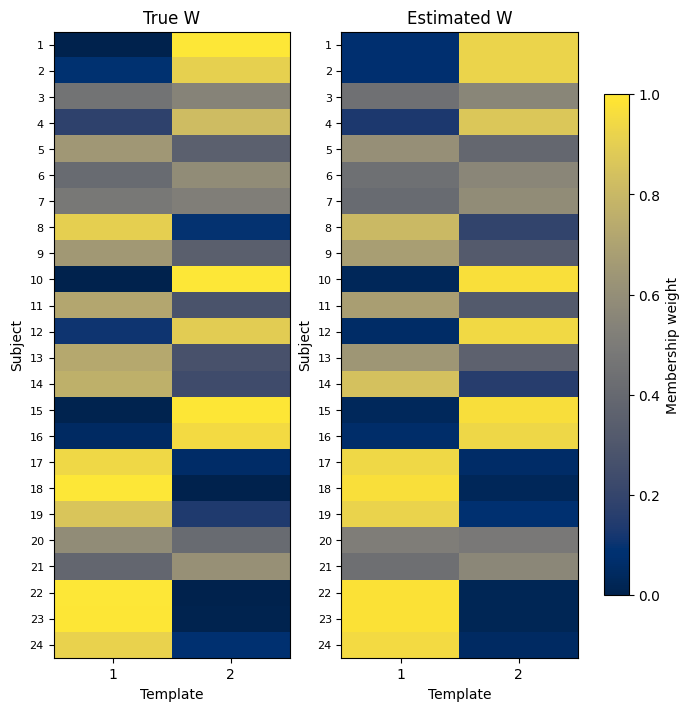

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(6.8, 7), constrained_layout=True)
for ax, values, title in zip(axes, [W_true, W_est], ["True W", "Estimated W"]):
    heatmap = ax.imshow(values, cmap="cividis", vmin=0, vmax=1,
                        aspect="auto", interpolation="nearest")
    ax.set(title=title, xlabel="Template", ylabel="Subject")
    ax.set_xticks(np.arange(templates), np.arange(1, templates + 1))
    ax.set_yticks(np.arange(subjects), np.arange(1, subjects + 1))
    ax.tick_params(axis="y", labelsize=8)
fig.colorbar(heatmap, ax=axes.tolist(), shrink=0.8, label="Membership weight")
plt.show()

## Entrywise agreement

The scatter plots summarize the same template and membership comparisons. Points on the dashed diagonal match their generating values exactly.

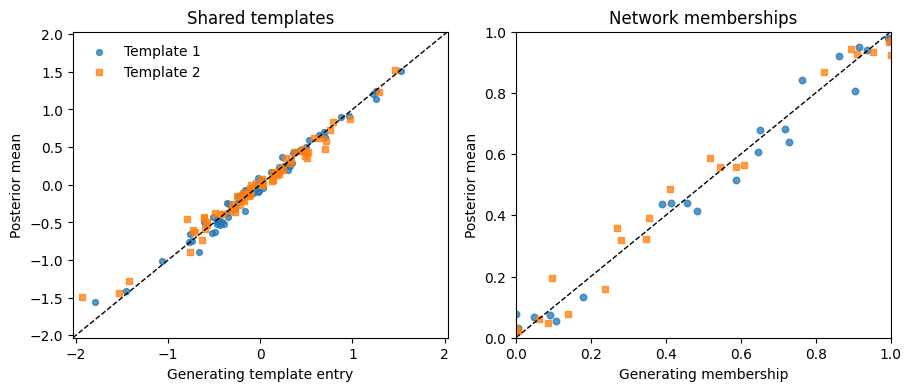

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), constrained_layout=True)

colors = ["tab:blue", "tab:orange"]
markers = ["o", "s"]

for template, (color, marker) in enumerate(zip(colors, markers)):
    axes[0].scatter(Q_true[template], summary["Q_mean"][template],
                    s=18, color=color, marker=marker, alpha=0.75,
                    label=f"Template {template + 1}")
    axes[1].scatter(W_true[:, template], summary["W_mean"][:, template],
                    s=22, color=color, marker=marker, alpha=0.75)

bound = max(np.abs(Q_true).max(), np.abs(summary["Q_mean"]).max()) * 1.05
axes[0].plot([-bound, bound], [-bound, bound], "k--", lw=1)
axes[0].set(xlabel="Generating template entry", ylabel="Posterior mean",
            title="Shared templates", xlim=(-bound, bound), ylim=(-bound, bound))
axes[0].legend(frameon=False)

axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set(xlabel="Generating membership", ylabel="Posterior mean",
            title="Network memberships", xlim=(0, 1), ylim=(0, 1))

plt.show()

For your own networks, construct `Z`, transformed `Y`, and the observation mask in the same upper-triangle order. Estimate transformation constants from training data. The [HCP data guide](hcp/DATA.md) describes the structural-connectome input format and cohort workflow.